# Hallazgos y decisiones del primer notebook:


.....


In [15]:
#Importar paqueterías:
import pandas as pd              
import duckdb                     
import matplotlib.pyplot as plt  
import seaborn as sns 

#Conexión con el archivo de la base:
con = duckdb.connect("../data/db/delitos_LA.duckdb", read_only=True)  

# Pregunta 1: ¿cuáles son los 3 delitos más frecuentes en el acumulado 2020–2023, según el sexo de la víctima?

In [16]:
#Ejecuta una consulta SQL
del_sexo = con.execute("SELECT * FROM model.del_sexo").df()   
del_area = con.execute("SELECT * FROM model.del_area").df()

In [26]:
delitos_frecuentes_muj = (del_sexo[del_sexo["sexo_vic"] == "F"]          
          .sort_values("n_delitos", ascending=False)     
          .head(3))                                      

delitos_frecuentes_hom = (del_sexo[del_sexo["sexo_vic"] == "M"]          
          .sort_values("n_delitos", ascending=False)     
          .head(3))                                      

print("Los 3 delitos más frecuentes en mujeres durante el periodo 2020-2023:")      
print(delitos_frecuentes_muj)          
print("\nLos 3 delitos más frecuentes en hombres durante el periodo 2020-2023:")   
print(delitos_frecuentes_hom)          

Los 3 delitos más frecuentes en mujeres durante el periodo 2020-2023:
    sexo_vic                             delito  n_delitos
251        F  INTIMATE PARTNER - SIMPLE ASSAULT      33193
65         F           BATTERY - SIMPLE ASSAULT      32641
48         F                  THEFT OF IDENTITY      32435

Los 3 delitos más frecuentes en hombres durante el periodo 2020-2023:
    sexo_vic                                          delito  n_delitos
235        M                        BATTERY - SIMPLE ASSAULT      36359
47         M  ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT      35579
252        M                           BURGLARY FROM VEHICLE      30244


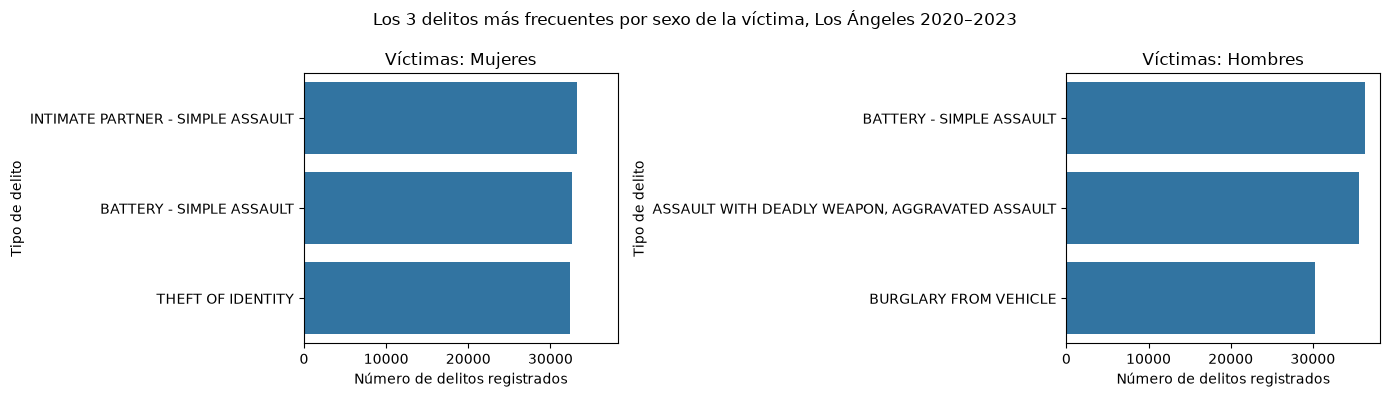

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)    

# Gráfica de la izquierda: mujeres
sns.barplot(data=df_muj, x="n_delitos", y="delito", ax=axes[0])   
axes[0].set_title("Víctimas: Mujeres")                            
axes[0].set_xlabel("Número de delitos registrados")             
axes[0].set_ylabel("Tipo de delito")                             

# Gráfica de la derecha: hombres
sns.barplot(data=df_hom, x="n_delitos", y="delito", ax=axes[1])   
axes[1].set_title("Víctimas: Hombres")                            
axes[1].set_xlabel("Número de delitos registrados")               
axes[1].set_ylabel("Tipo de delito")                              

fig.suptitle("Los 3 delitos más frecuentes por sexo de la víctima, Los Ángeles 2020–2023")  
fig.tight_layout()                                                       
fig.savefig("../docs/imgs/figura_01.png", dpi=160, bbox_inches="tight")  
plt.show()                                                              

# Interpretación de gráfica 1:

En las mujeres, el delito más común durante el periodo 2020-2023 fue la agresión simple por parte de la pareja íntima (33,193 casos), seguido de la agresión física simple (32,641) y el robo de identidad (32,435). 

En los hombres, el delito más común durante el periodo 2020-2023 fue la agresión física simple (36,359), la agresión con arma mortal (35,579) y el robo al interior de vehículos (32,344). 

Esto sugiere que, a diferencia de los hombres, el principal delito contra la mujer ocurre dentro del contexto de la violencia de género, la cual suele asociarse con factores socioculturales, como el machismo, y con fallas institucionales en materia de seguridad y justicia. 

No obstante, una limitación de estos datos es que, por sí solos, no permiten comprobar las causas de la violencia de género presente en Los Ángeles. 

# Los 3 delitos más frecuentes por sexo de la víctima, ¿ocurren de manera homogénea entre las 21 áreas geográficas o se concentran en áreas específicas?

In [27]:
area_muj = del_area[(del_area["sexo_vic"] == "F") & (del_area["delito"].isin(df_muj["delito"]))]  
area_hom = del_area[(del_area["sexo_vic"] == "M") & (del_area["delito"].isin(df_hom["delito"]))]  

areas = sorted(del_area["nom_area"].unique()) 
print(areas)
print(len(areas)) 

['77th Street', 'Central', 'Devonshire', 'Foothill', 'Harbor', 'Hollenbeck', 'Hollywood', 'Mission', 'N Hollywood', 'Newton', 'Northeast', 'Olympic', 'Pacific', 'Rampart', 'Southeast', 'Southwest', 'Topanga', 'Van Nuys', 'West LA', 'West Valley', 'Wilshire']
21


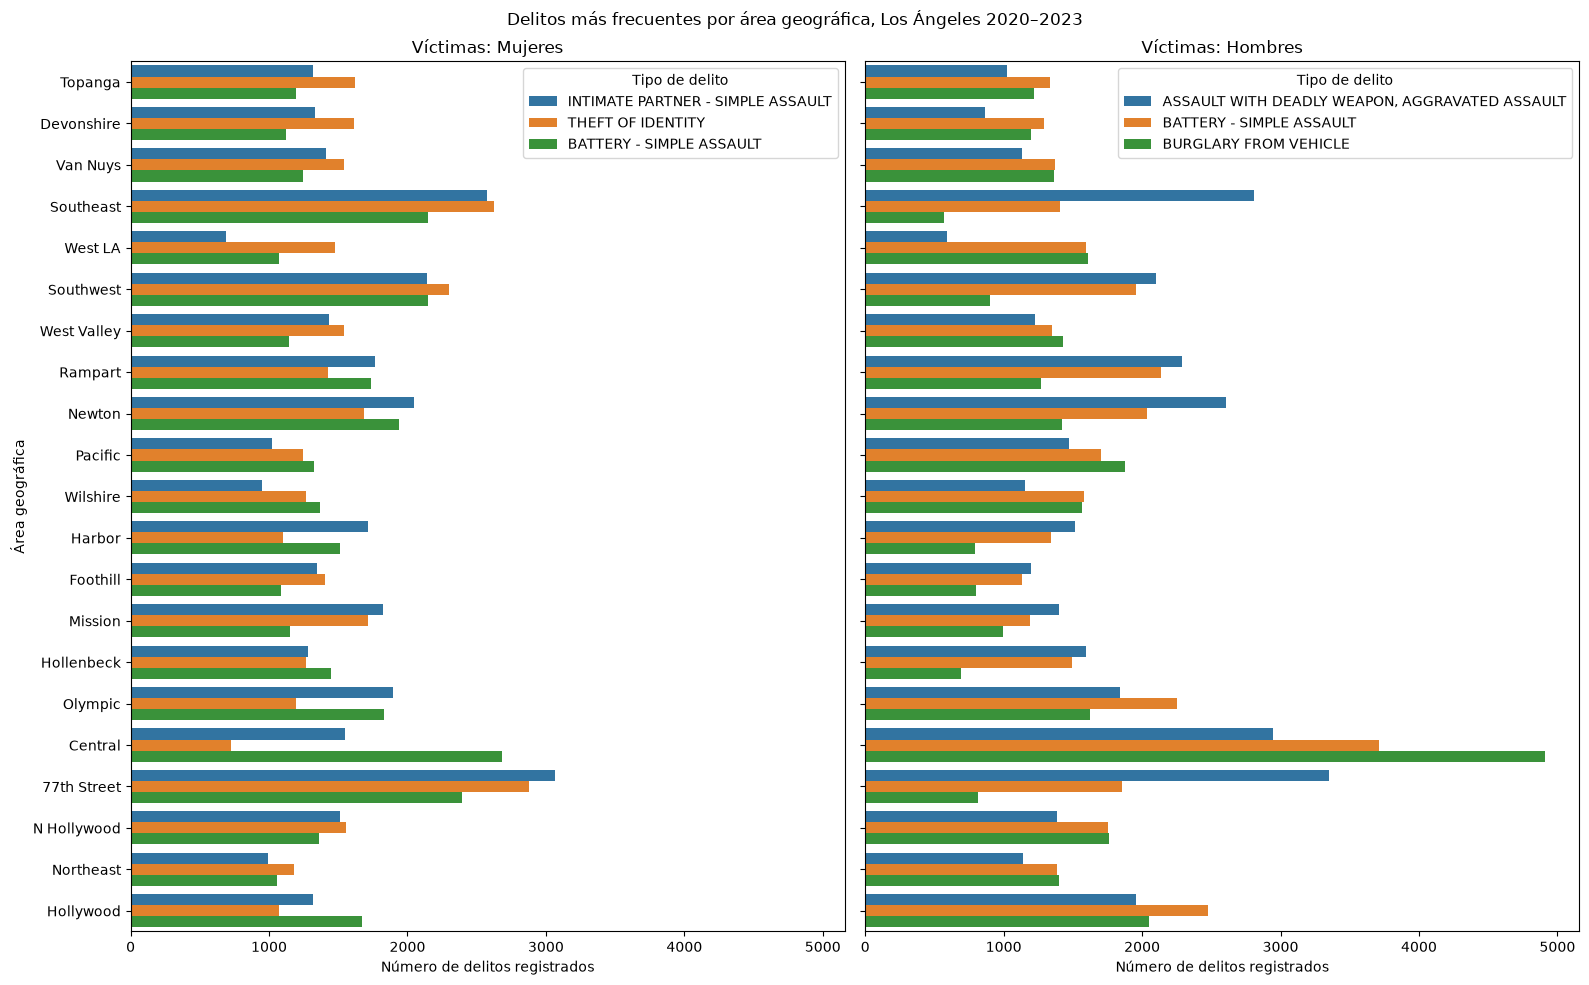

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True, sharey=True)  

# Gráfica de la izquierda: mujeres
sns.barplot(data=area_muj, x="n_delitos", y="nom_area", hue="delito", ax=axes[0])  
axes[0].set_title("Víctimas: Mujeres")                    
axes[0].set_xlabel("Número de delitos registrados")        
axes[0].set_ylabel("Área geográfica")                      
axes[0].legend(title="Tipo de delito")                    

# Gráfica de la derecha: hombres
sns.barplot(data=area_hom, x="n_delitos", y="nom_area", hue="delito", ax=axes[1])
axes[1].set_title("Víctimas: Hombres")
axes[1].set_xlabel("Número de delitos registrados")
axes[1].set_ylabel("")                                    
axes[1].legend(title="Tipo de delito")

fig.suptitle("Delitos más frecuentes por área geográfica, Los Ángeles 2020–2023")  
fig.tight_layout()                                                       
fig.savefig("../docs/imgs/figura_02.png", dpi=160, bbox_inches="tight")  
plt.show()                                                               

# Interpretación de gráfica 2:

En las mujeres, la agresión por pareja íntima y el robo de identidad se concentran en 77th Street, Southeast y Southwest. En 77th Street destaca la agresión por pareja íntima, en En Southeast el robo de identidad y en Central la agresión física simple. 

En los hombres, el area que más destaca para los 3 delitos es Central, interpretándola como un foco rojo. Aunque la agresión con arma mortal también se concentra de manera importante en 77th Street, Southeast y Newton; el robo al interior de vehículos en Pacific y la agresión simple en Hollywood y Olimpic.

De manera general, esto sugiere que el top 3 de los delitos más frecuentes para ambos sexos se concentran prinicpalmente en 77th Street y Southeast. 

Una limitación importante de estos datos es que, al tener las áreas distinta cantidad de población, más casos no significan necesariamente mayor riesgo. Es decir, los datos corresponden a cifras absolutas, más no a tasas por cada 10k o 100k habitantes, las cuales serían lo apropiado para poder comparar entre áreas. Por ello, si bien las cifras aboslutas orientan sobre el panorama delictivo de Los Ángeles, no se puede afirmar con seguridad que un área es más violenta que otra.  